# market-risk-engine: analysis

Reads the outputs written by `run_all.py` (run that first, from the project root). All numbers below come from `results/`.

In [1]:
import json
from pathlib import Path

import pandas as pd
from IPython.display import Image, display

R = Path('..') / 'results'
meta = json.loads((R / 'run_metadata.json').read_text())
assert not meta['synthetic'], 'results were produced from SYNTHETIC data'
keys = ['data_source', 'price_start', 'price_end', 'n_return_obs', 'backtest_start',
        'backtest_end', 'backtest_n_obs', 'ml_backend', 'ml_floor_hits',
        'garch_not_converged']
{k: meta[k] for k in keys}

{'data_source': 'cache',
 'price_start': '2018-01-02',
 'price_end': '2026-11-20',
 'n_return_obs': 2234,
 'backtest_start': '2020-04-03',
 'backtest_end': '2026-11-20',
 'backtest_n_obs': 1668,
 'ml_backend': 'lightgbm',
 'ml_floor_hits': 0,
 'garch_not_converged': 0}

## Full-sample 1-day 99% VaR and ES

In [2]:
pd.read_csv(R / 'full_sample_var_es.csv')

,method,var,es
0,historical,0.027603,0.042056
1,parametric,0.022630,0.026009
2,monte_carlo,0.023390,0.026594


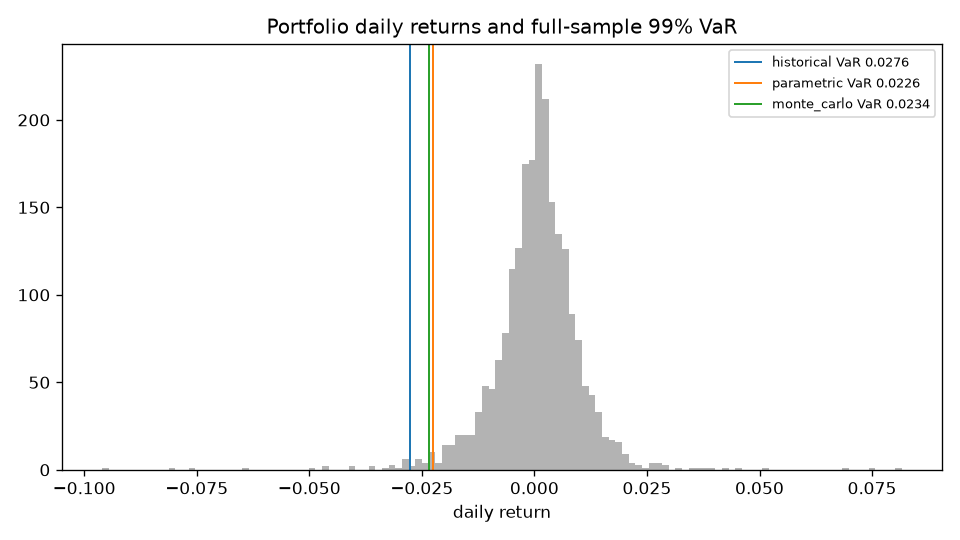

In [3]:
display(Image(R / 'figures' / 'return_distribution.png'))

## Rolling backtest (500-day window): Kupiec, Christoffersen independence and conditional coverage

All six methods on the common period:

In [4]:
pd.read_csv(R / 'backtest_summary.csv')

,method,start,end,n_obs,breaches,expected,breach_rate,kupiec_lr,kupiec_p,christoffersen_lr,christoffersen_p,cc_lr,cc_p,mean_var
0,historical,2020-04-03,2026-11-20,1668,14,16.68,0.008393,0.460061,4.975950e-01,2.769810,0.096058,3.22663,1.992260e-01,0.030923
1,parametric,2020-04-03,2026-11-20,1668,26,16.68,0.015588,4.494780,3.399850e-02,7.589280,0.005872,12.09540,2.363310e-03,0.023114
2,monte_carlo,2020-04-03,2026-11-20,1668,25,16.68,0.014988,3.635260,5.656770e-02,3.809690,0.050957,7.45506,2.405210e-02,0.023130
3,garch,2020-04-03,2026-11-20,1668,31,16.68,0.018585,9.910700,1.643200e-03,0.296216,0.586265,10.22430,6.022970e-03,0.019724
4,ml,2020-04-03,2026-11-20,1668,46,16.68,0.027578,35.211400,2.957940e-09,0.381613,0.536741,35.62880,1.833590e-08,0.018368
5,har,2020-04-03,2026-11-20,1668,31,16.68,0.018585,9.910700,1.643200e-03,5.622520,0.017731,15.55070,4.199710e-04,0.021003


Classical methods over their full forecast period (the common period starts later because the volatility models need 66 days of feature history):

In [5]:
pd.read_csv(R / 'backtest_summary_full_period.csv')

,method,start,end,n_obs,breaches,expected,breach_rate,kupiec_lr,kupiec_p,christoffersen_lr,christoffersen_p,cc_lr,cc_p,mean_var
0,historical,2019-12-30,2026-11-20,1734,21,17.34,0.012111,0.73108,0.392533,5.24297,0.022036,5.97833,5.032950e-02,0.030752
1,parametric,2019-12-30,2026-11-20,1734,37,17.34,0.021338,16.99080,0.000038,20.80040,0.000005,37.81420,6.148310e-09,0.023018
2,monte_carlo,2019-12-30,2026-11-20,1734,36,17.34,0.020761,15.47980,0.000083,16.48400,0.000049,31.98560,1.133460e-07,0.023033


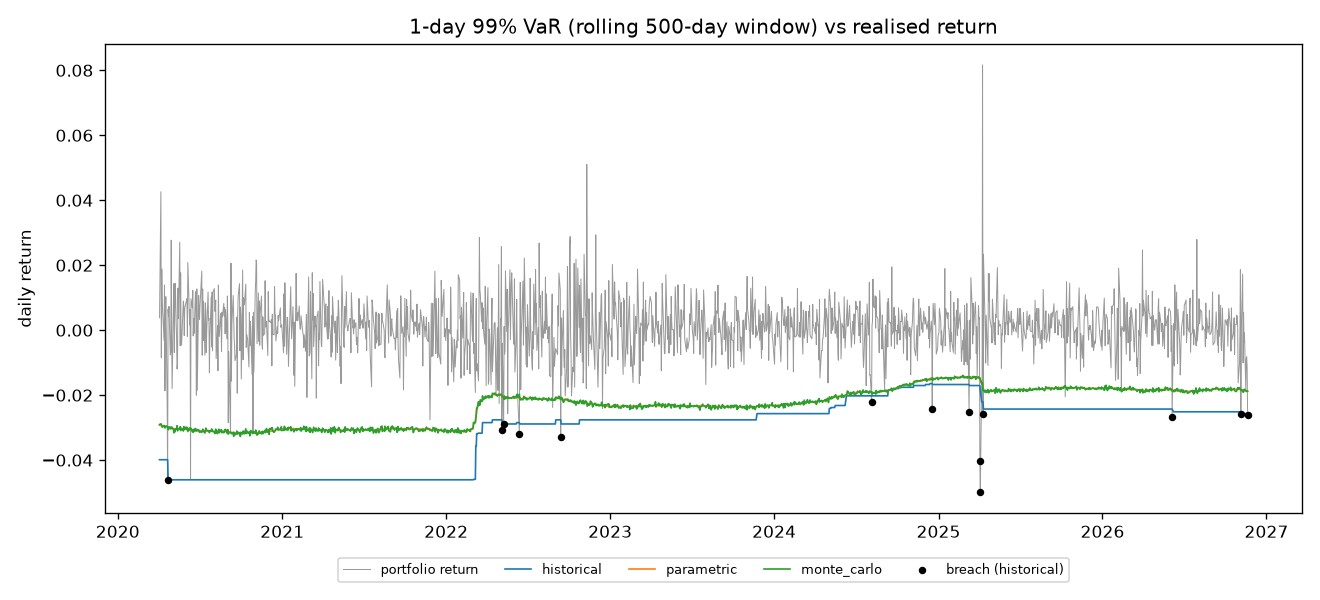

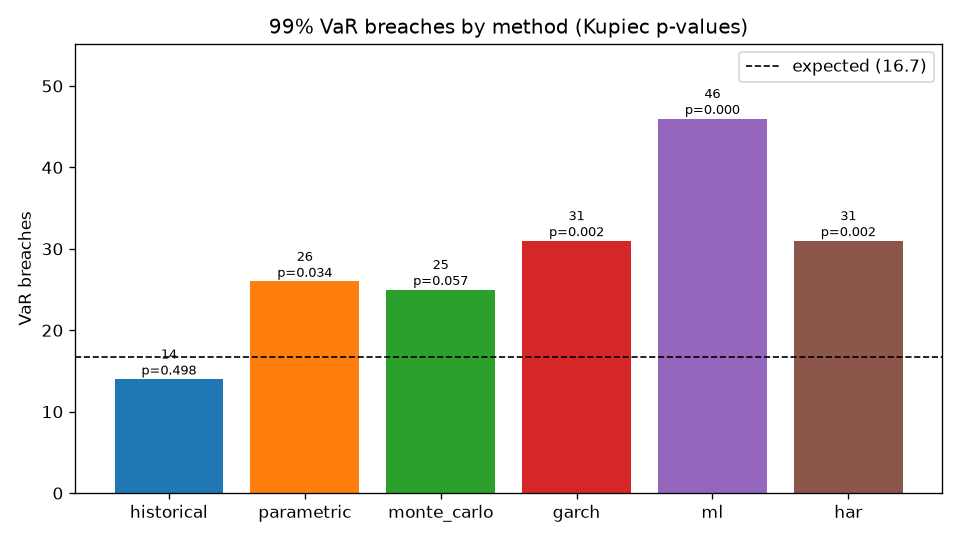

In [6]:
display(Image(R / 'figures' / 'var_backtest.png'))
display(Image(R / 'figures' / 'breaches.png'))

## Volatility forecasts: GARCH(1,1) vs gradient boosting vs HAR-OLS baseline

In [7]:
pd.read_csv(R / 'vol_metrics.csv')

,model,n_obs,rmse_var_pct2,qlike
0,garch,1668,2.37174,0.633100
1,ml,1668,2.42262,0.753192
2,har,1668,2.48438,1.517530


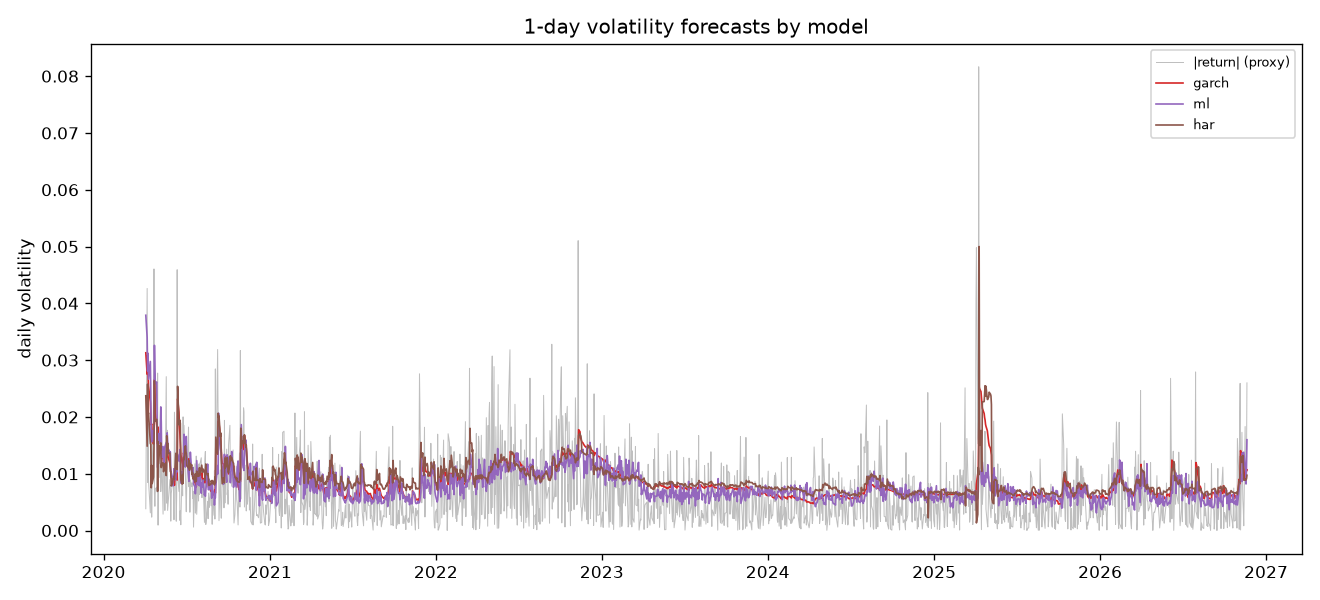

In [8]:
display(Image(R / 'figures' / 'vol_forecasts.png'))

In [9]:
vols = pd.read_csv(R / 'vol_forecasts.csv', index_col=0, parse_dates=True)
vols[['garch', 'ml', 'har']].describe()

,garch,ml,har
count,1668.000000,1668.000000,1668.000000
mean,0.008478,0.007896,0.009028
std,0.003183,0.003203,0.003038
min,0.004645,0.003092,0.001342
25%,0.006341,0.005800,0.007199
50%,0.007505,0.006982,0.008214
75%,0.009663,0.009333,0.009947
max,0.031299,0.037905,0.050001
